# 01 — Simulate the data

**Question this notebook answers:** Can we build a fake subscription business where we *know* the true
retention curve, so every later method can be graded against the real answer?

**The story we're simulating**
1. Each customer is secretly **loyal** (~7% monthly churn) or **flaky** (~45%). The models never see this.
2. Observed features **multiply** that churn: `channel`, `plan`, `discount_at_signup`.
3. Each individual's churn is **constant**, so their lifetime is Geometric(p).
4. Signups are spread over 24 months and we look at the data at month 24, so recent customers are **censored**
   (still active, and we don't know when they'll leave).

**What we expect to see:** each customer's churn rate is flat, but the *population's* churn rate should
**fall over time**, because flaky customers leave first. That one fact is why the naive constant-churn
model will fail later.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from simulate import simulate_customers, true_retention_curve, DEFAULT_PARAMS

SEED = 42
customers, truth = simulate_customers(n_customers=4000, seed=SEED)

Path("../data").mkdir(exist_ok=True)
customers.to_csv("../data/customers.csv", index=False)
truth.to_csv("../data/truth.csv", index=False)   # evaluation only, never a model input

customers.head()

,customer_id,signup_month,channel,plan,discount_at_signup,months_observed,churned,monthly_margin
0,0,2,referral,monthly,0,1,1,14.0
1,1,18,paid_social,annual,0,6,0,11.0
2,2,15,referral,monthly,1,8,1,14.0
3,3,10,search,annual,1,5,1,11.0
4,4,10,paid_social,annual,0,4,1,11.0


## What the analyst sees
One row per customer. `months_observed` is the duration and `churned` is the event flag
(0 = still active at the cutoff, i.e. censored).

In [2]:
print(f"{len(customers):,} customers")
print(f"Churn observed for {customers.churned.mean():.1%}; censored (still active) for {1 - customers.churned.mean():.1%}")
customers.describe(include="all").T[["count", "unique", "top", "mean", "min", "max"]]

4,000 customers
Churn observed for 70.2%; censored (still active) for 29.8%


,count,unique,top,mean,min,max
customer_id,4000.0,NaN,NaN,1999.5,0.0,3999.0
signup_month,4000.0,NaN,NaN,11.52775,0.0,23.0
channel,4000,3,paid_social,NaN,NaN,NaN
plan,4000,2,monthly,NaN,NaN,NaN
discount_at_signup,4000.0,NaN,NaN,0.3035,0.0,1.0
months_observed,4000.0,NaN,NaN,5.4405,1.0,24.0
churned,4000.0,NaN,NaN,0.70225,0.0,1.0
monthly_margin,4000.0,NaN,NaN,13.253,11.0,14.0


## Sanity check 1 — the hidden types
Does the truth table match what we designed? Loyal should be near 7% and flaky near 45%. The averages come out a bit
higher because the feature multipliers push most customers' churn upward.

In [3]:
df = customers.merge(truth, on="customer_id")
df.groupby("customer_type").agg(
    n=("customer_id", "size"),
    share=("customer_id", lambda s: len(s) / len(df)),
    mean_true_churn=("true_monthly_churn", "mean"),
    mean_true_lifetime=("true_lifetime", "mean"),
).round(3)

,n,share,mean_true_churn,mean_true_lifetime
customer_type,,,,
flaky,1547,0.387,0.499,2.352
loyal,2453,0.613,0.076,14.711


## Sanity check 2 — features shift churn the way we designed
We compare the **true** mean churn by segment with the designed multipliers.

We also show the naive "% churned" column, which is what you'd get from just counting churners. **It mixes two
things:** how risky a segment is, and how long we happened to watch it. That second part comes from censoring,
which is why notebooks 03 and later need survival methods.

In [4]:
for col in ["channel", "plan", "discount_at_signup"]:
    tbl = df.groupby(col).agg(
        n=("customer_id", "size"),
        true_monthly_churn=("true_monthly_churn", "mean"),
        naive_pct_churned=("churned", "mean"),
    ).round(3)
    display(tbl)

print("Designed multipliers:")
print("  channel :", DEFAULT_PARAMS["channel_mult"])
print("  plan    :", DEFAULT_PARAMS["plan_mult"])
print("  discount:", DEFAULT_PARAMS["discount_mult"])

,n,true_monthly_churn,naive_pct_churned
channel,,,
paid_social,1852,0.294,0.744
referral,760,0.150,0.611
search,1388,0.215,0.697


,n,true_monthly_churn,naive_pct_churned
plan,,,
annual,996,0.158,0.609
monthly,3004,0.266,0.733


,n,true_monthly_churn,naive_pct_churned
discount_at_signup,,,
0,2786,0.210,0.677
1,1214,0.308,0.759


Designed multipliers:
  channel : {'paid_social': 1.3, 'search': 1.0, 'referral': 0.7}
  plan    : {'monthly': 1.0, 'annual': 0.6}
  discount: 1.4


Ratios of true churn line up with the multipliers. For example, referral / search ≈ 0.70 and annual / monthly ≈ 0.60.
They're not exact, because the loyal/flaky mix varies a little by segment through random sampling.

## Sanity check 3 — censoring depends on signup date
The later someone signed up, the less time we've had to watch them, so the more likely they're still "active"
in our data. If a method ignores this, recent cohorts look artificially loyal (or, if censored rows are counted
as churned, artificially bad).

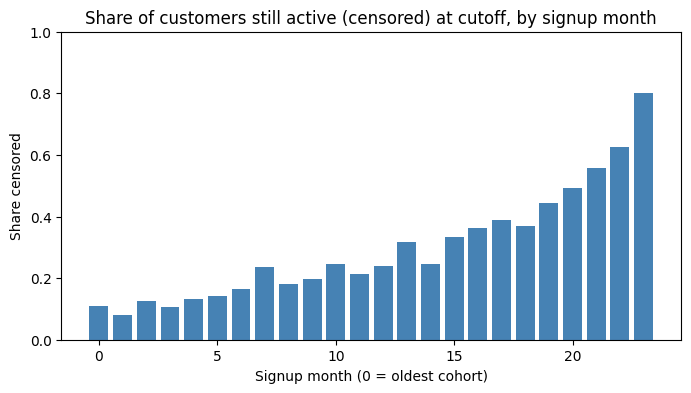

In [5]:
cens = 1 - customers.groupby("signup_month")["churned"].mean()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(cens.index, cens.values, color="steelblue")
ax.set_title("Share of customers still active (censored) at cutoff, by signup month")
ax.set_xlabel("Signup month (0 = oldest cohort)")
ax.set_ylabel("Share censored")
ax.set_ylim(0, 1)
plt.show()

**Takeaway:** the oldest cohorts are almost fully observed, while the newest cohorts are mostly censored.
The amount of missing information depends heavily on cohort age.

## The key idea: heterogeneity makes population churn fall over time

The true population retention curve is the average of each customer's own curve:

$$S(t) = \frac{1}{N}\sum_i (1 - p_i)^t$$

In words: the expected share of customers still active after *t* months.

Let's compare it with what a naive analyst would do: take month-1 churn and assume it stays constant forever,
$S_{naive}(t) = (1 - h_1)^t$.

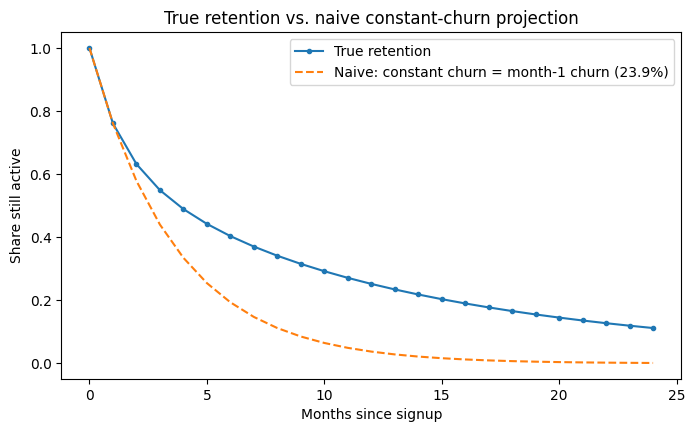

,true,naive_constant_churn
3,0.549,0.440
6,0.404,0.194
12,0.252,0.038
24,0.112,0.001


In [6]:
S_true = true_retention_curve(truth, horizon=24)
h1 = 1 - S_true[1]
S_naive = pd.Series((1 - h1) ** S_true.index.to_numpy(), index=S_true.index)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(S_true.index, S_true.values, marker="o", ms=3, label="True retention")
ax.plot(S_naive.index, S_naive.values, ls="--", label=f"Naive: constant churn = month-1 churn ({h1:.1%})")
ax.set_title("True retention vs. naive constant-churn projection")
ax.set_xlabel("Months since signup")
ax.set_ylabel("Share still active")
ax.legend()
plt.show()

pd.DataFrame({"true": S_true, "naive_constant_churn": S_naive}).loc[[3, 6, 12, 24]].round(3)

**Takeaway:** at month 24 the truth is about 11% retained, while the naive model says about 0.1%. Assuming constant
churn sharply **underestimates** long-run retention, and therefore LTV.

Why? Let's look at the population's monthly churn rate (the hazard) month by month.

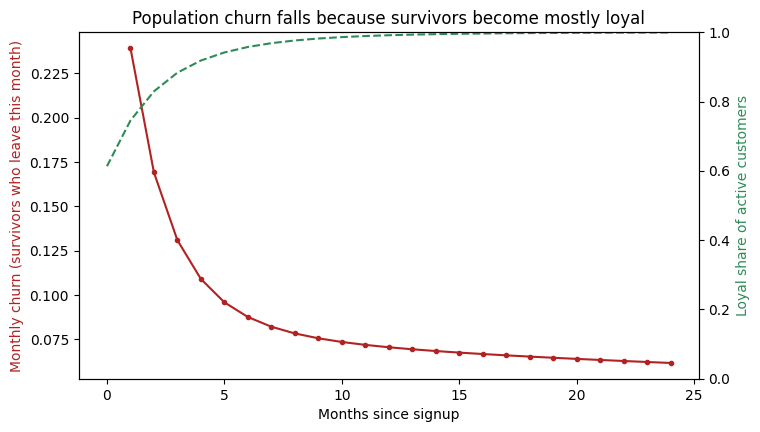

In [7]:
hazard = (1 - S_true / S_true.shift(1)).dropna()
# Expected survivors at month t, split by hidden type
surv = (1 - truth["true_monthly_churn"].to_numpy()[:, None]) ** np.arange(25)
is_loyal = (truth["customer_type"] == "loyal").to_numpy()[:, None]
loyal_share = pd.Series((surv * is_loyal).sum(axis=0) / surv.sum(axis=0))

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(hazard.index, hazard.values, marker="o", ms=3, color="firebrick", label="Population monthly churn")
ax1.set_xlabel("Months since signup")
ax1.set_ylabel("Monthly churn (survivors who leave this month)", color="firebrick")
ax2 = ax1.twinx()
ax2.plot(loyal_share.index, loyal_share.values, color="seagreen", ls="--", label="Loyal share of survivors")
ax2.set_ylabel("Loyal share of active customers", color="seagreen")
ax2.set_ylim(0, 1)
ax1.set_title("Population churn falls because survivors become mostly loyal")
plt.show()

**Takeaway:** no individual changed their behavior, yet population churn drops from about 24% in month 1 to about 6% by month 24.
That's because the loyal share of the remaining customers climbs from about 60% to nearly 100%. That's the
**mix effect**. A method that can represent this decline (sBG, Weibull with shape < 1) should beat constant churn.

## Assumptions baked into this simulation (and what they make easy or hard)
- **Constant individual churn.** Real customers may churn more around renewal dates or after a price change. That's fine for learning.
- **Features multiply churn the same way at every tenure.** That's proportional hazards by construction, so Cox should
  do well here. Notebook 04 will break this on purpose.
- **Annual plan treated as a lower monthly churn**, not as a 12-month lock-in. A real annual plan can only churn at
  renewal, which would create spikes at months 12 and 24.
- **The loyal/flaky type is independent of features.** So part of the variation in churn is unobservable "frailty". Expect
  Cox hazard ratios to be pulled toward 1 because of it, which we'll test in notebook 04.
- **Customer mix is stable across cohorts.** Shifting it later is one of the optional experiments.

## What I learned (fill in)
-
-
- 